# PROJECT SPRINT 15 SQL

El coronavirus tomó al mundo entero por sorpresa, cambiando la rutina diaria de todos y todas. Los habitantes de las ciudades ya no pasaban su tiempo libre fuera, yendo a cafés y centros comerciales; sino que más gente se quedaba en casa, leyendo libros. Eso atrajo la atención de las startups (empresas emergentes) que se apresuraron a desarrollar nuevas aplicaciones para los amantes de los libros.

Te han dado una base de datos de uno de los servicios que compiten en este mercado. Contiene datos sobre libros, editoriales, autores y calificaciones de clientes y reseñas de libros. Esta información se utilizará para generar una propuesta de valor para un nuevo producto.

### Descripción de los datos

**`books`**

Contiene datos sobre libros:

- `book_id`: identificación del libro
- `author_id`: identificación del autor o autora
- `title`: título
- `num_pages`: número de páginas
- `publication_date`: fecha de la publicación
- `publisher_id`: identificación de la editorial

**`authors`**

Contiene datos sobre autores:

- `author_id`: identificación del autor o autora
- `author`: el autor o la autora

**`publishers`**

Contiene datos sobre editoriales:

- `publisher_id`: identificación de la editorial
- `publisher`: la editorial

**`ratings`**

Contiene datos sobre las calificaciones de usuarios:

- `rating_id`: identificación de la calificación
- `book_id`: identificación del libro
- `username`: el nombre del usuario que revisó el libro
- `rating`: calificación

**`reviews`**

Contiene datos sobre las reseñas de los y las clientes:

- `review_id`: identificación de la reseña
- `book_id`: identificación del libro
- `username`: el nombre del usuario que revisó el libro
- `text`: el texto de la reseña

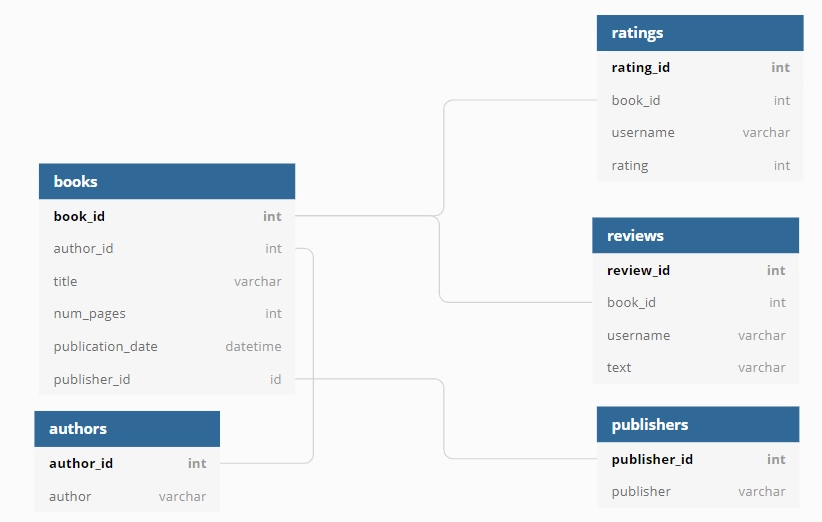

Relaciones entre tablas
* Books se relaciona con:
    * *Authors* a través de: books.author_id > authors.author_id
    * *Ratings* a través de: books.book_id > ratings.book_id
    * *Reviews* a través de: books.book_id > reviews.book_id
    * *Publishers* a través de: books.publisher_id > publishers.publisher_id

Todas las tablas se pueden unir a través de books y algunas subconsultas. 

## Conectarse a la base de datos 

In [1]:
# importar librerías y conexión a la base de datos

import pandas as pd
from sqlalchemy import create_engine


db_config = {'user': 'practicum_student',                       # nombre de usuario
             'pwd': 'XXXXXXXXXXXXXXXXXXXXXXXX',                 # contraseña
             'host': 'XXXXXXXXXXXXXXXXXXXXXXX',
             'port': 5432,                                      # puerto de conexión
             'db': 'data-analyst-final-project-db'}             # nombre de la base de datos

connection_string = 'postgresql://{}:{}@{}:{}/{}'.format(db_config['user'],
                                                                       db_config['pwd'],
                                                                       db_config['host'],
                                                                       db_config['port'],
                                                                       db_config['db'])

engine = create_engine(connection_string, connect_args={'sslmode':'require'})

##### Funciones para ejecutar tareas

In [2]:
# Creamos función para explorar archivos, similar a df.head()

def explore_table (table):                              # La función recibe como parámetro la tabla a explorar 
    try:                                                # Si la conexión es exitosa
        query = f'SELECT * FROM {table};'               # Introducimos la consulta de interés
        raw_data = pd.read_sql(query, con = engine)     # Ejecutamos la consulta
        return raw_data                                 # Devuelve la consulta
    except Exception as e:                              # Si la conexión no es exitosa
        print(f'Error de exploración de {table}: {e}')
        return None

In [3]:
# Creamos función para imprimir la consulta 

def print_query (query):                                # La función recibe un query/consulta como parámetro
    try:
        resultados = pd.read_sql(query, con=engine)     # Ejecutamos la consulta
        print(resultados)                               # Imprime el resultado de la consulta
    except Exception as e:
        print(f'Error al ejecutar la consulta: {e}')

##### Mostrar las tablas de la base de datos

In [4]:
# Tabla books

books = 'books'

explore_table(books).info()
explore_table(books).head(5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   book_id           1000 non-null   int64 
 1   author_id         1000 non-null   int64 
 2   title             1000 non-null   object
 3   num_pages         1000 non-null   int64 
 4   publication_date  1000 non-null   object
 5   publisher_id      1000 non-null   int64 
dtypes: int64(4), object(2)
memory usage: 47.0+ KB


,book_id,author_id,title,num_pages,publication_date,publisher_id
0,1,546,'Salem's Lot,594,2005-11-01,93
1,2,465,1 000 Places to See Before You Die,992,2003-05-22,336
2,3,407,13 Little Blue Envelopes (Little Blue Envelope...,322,2010-12-21,135
3,4,82,1491: New Revelations of the Americas Before C...,541,2006-10-10,309
4,5,125,1776,386,2006-07-04,268


Mostramos las primeras 5 filas de la tabla 'books'. Esta tabla contiene todos los libros identificados con un book_id, ligado a su autor con su author_id, el título, número de páginas, fecha de publicación y la editorial. La tabla dentro de la base de datos contiene 1000 valores.

In [5]:
# Tabla authors

authors = 'authors'

explore_table(authors).info()
explore_table(authors).head(5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 636 entries, 0 to 635
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   author_id  636 non-null    int64 
 1   author     636 non-null    object
dtypes: int64(1), object(1)
memory usage: 10.1+ KB


,author_id,author
0,1,A.S. Byatt
1,2,Aesop/Laura Harris/Laura Gibbs
2,3,Agatha Christie
3,4,Alan Brennert
4,5,Alan Moore/David Lloyd


Mostramos las primeras 5 filas de 'authors'. Esta tabla contiene todos los autores con su respectivo author_id. La tabla dentro de la base de datos tiene 636 valores.

In [6]:
# Tabla ratings

ratings = 'ratings'

explore_table(ratings).info()
explore_table(ratings).head(5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6456 entries, 0 to 6455
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   rating_id  6456 non-null   int64 
 1   book_id    6456 non-null   int64 
 2   username   6456 non-null   object
 3   rating     6456 non-null   int64 
dtypes: int64(3), object(1)
memory usage: 201.9+ KB


,rating_id,book_id,username,rating
0,1,1,ryanfranco,4
1,2,1,grantpatricia,2
2,3,1,brandtandrea,5
3,4,2,lorichen,3
4,5,2,mariokeller,2


In [7]:
# Encontramos la calificación más alta posible/registrada

max_rating = ''' 
SELECT MAX (rating) AS max_rating
FROM ratings;
'''

print('La calificación más alta posible es:')
print_query(max_rating)

La calificación más alta posible es:
   max_rating
0           5


Desplegamos las primeras 5 filas de 'ratings'. Tenemos información sobre el registro del rating, book_id, el nombre del usuario que dio la calificación y la nota. De igual manera, imprimimos el valor máximo de rating posible, hallando que el valor más alto es 5. Esta tabla tiene 6456 registros.

In [8]:
# Tabla reviews

reviews = 'reviews'

explore_table(reviews).info()
explore_table(reviews).head(5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2793 entries, 0 to 2792
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review_id  2793 non-null   int64 
 1   book_id    2793 non-null   int64 
 2   username   2793 non-null   object
 3   text       2793 non-null   object
dtypes: int64(2), object(2)
memory usage: 87.4+ KB


,review_id,book_id,username,text
0,1,1,brandtandrea,Mention society tell send professor analysis. ...
1,2,1,ryanfranco,Foot glass pretty audience hit themselves. Amo...
2,3,2,lorichen,Listen treat keep worry. Miss husband tax but ...
3,4,3,johnsonamanda,Finally month interesting blue could nature cu...
4,5,3,scotttamara,Nation purpose heavy give wait song will. List...


Mostramos las 5 filas de 'reviews'. Encontramos el número de review, el book_id alque se le dio la reseña, el nombre de usuario y su respectiva reseña de texto. Esta tabla contiene 2793 registros.

In [9]:
# Tabla publishers

publishers = 'publishers'

explore_table(publishers).info()
explore_table(publishers).head(5)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 340 entries, 0 to 339
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   publisher_id  340 non-null    int64 
 1   publisher     340 non-null    object
dtypes: int64(1), object(1)
memory usage: 5.4+ KB


,publisher_id,publisher
0,1,Ace
1,2,Ace Book
2,3,Ace Books
3,4,Ace Hardcover
4,5,Addison Wesley Publishing Company


Esta tabla muestra los primeros 5 registros de las editoriales. Contiene el publisher_id así como el nombre de la editorial. Esta tabla contiene 340 registros.

## Ejecutar consultas

#### Libros publicados después del 1 de Enero 2000

In [10]:
# Número de libros publicados después de Enero 1 de 2000

books_2000 = ''' 
SELECT 
    COUNT (book_id) AS book_count        -- Contamos book_id
FROM 
    books                                -- De la tabla books
WHERE publication_date > '2000-01-01';   -- Filtrando para libros depués de 2000-01-01
'''
print('Libros publicados después de 01-01-2000')
print_query(books_2000)

Libros publicados después de 01-01-2000
   book_count
0         819


Se encontraron 819 libros publicados después del 01 de Enero de 2000.

##### Número de reseñas de usuarios y calificación promedio de cada libro

In [11]:
# Buscamos las reseñas y calificaciones promedio por cada libro

review_ratings = '''
SELECT 
    reviews.book_id,                                    -- Obtenemos el identificador del libro
    books.title,                                        -- Obtenemos el título del libro
    COUNT (review_id) AS num_reviews,                   -- Contamos cuántas reseñas hay 
    AVG(rating) AS avg_rating                           -- Sacamos el promedio de las calificaciones para ese libro
FROM
    reviews 
    INNER JOIN books ON reviews.book_id = books.book_id       -- Unimos books con reviews tomando book_id
    INNER JOIN ratings ON reviews.book_id = ratings.book_id   -- Unimos ratings con reviews tomando book_id
GROUP BY 
    reviews.book_id,                                    -- Agrupamos todas las reseñas y calficiaciones por book_id
    books.title;                                        -- Agrupamos todas las reseñsa y calificaciones por el título del libro
'''

print_query(review_ratings)

     book_id                                              title  num_reviews  \
0        412                   Lucy Sullivan Is Getting Married            4   
1        427                                Memoirs of a Geisha           30   
2        480  No Ordinary Time: Franklin and Eleanor Rooseve...            4   
3        873                       The Sorrows of Young Werther            4   
4        693                                       The Crucible           44   
..       ...                                                ...          ...   
989      569  Sideways Stories from Wayside School (Wayside ...            9   
990      792                                 The Maltese Falcon            9   
991      574                                Skinny Legs and All            4   
992      609           Swann's Way (In Search of Lost Time  #1)            4   
993      467  Narcissus in Chains (Anita Blake  Vampire Hunt...            4   

     avg_rating  
0      2.500000  
1  

Se encontró que para 994 libros hay por lo menos una reseña y 1 calificación. El número de reseñas varía, así como el promedio de las calificaciones. 

#### Editorial con más libros de más de 50 páginas

In [12]:
# Buscamos a las editoriales que publican más libros de más de 50 páginas

publisher_plus50 = '''
SELECT
    publishers.publisher_id,                -- Seleccionamos la columna de publisher_id 
    publishers.publisher,                   -- Seleccionamos el nombre de la editorial
    COUNT (book_id) AS num_books            -- Contamos cuántos libros hay por book_id
FROM
    publishers
    INNER JOIN books ON books.publisher_id = publishers.publisher_id    -- Unimos publishers con books a través de publisher_id
WHERE
    books.num_pages > 50                    -- Condicionamos a solo aquellos libros de más de 50 páginas
GROUP BY
    publishers.publisher_id,                -- Agrupamos el conteo de libros por publisher_id
    publishers.publisher                    -- Agrupamos el conteo de libros por nombre de la editorial
ORDER BY
    num_books DESC                          -- Ordenamos de manera descendiente
LIMIT
    3;                                      -- Limitamos a 1 para conocer la editorial con más títulos
'''

print_query(publisher_plus50)

   publisher_id                 publisher  num_books
0           212             Penguin Books         42
1           309                   Vintage         31
2           116  Grand Central Publishing         25


Después de condicionar a aquellas editoriales que solamente publican libros de más de 50 páginas, encontramos que **Penguin Books** es la que más títulos ha publicado con un total de 42. Dentro del top 3 están también *Vintage y Grand Central Publishing*.

#### Autor con calificación promedio más alta

Solamente se considerarán libros con al menos 50 calificaciones

In [13]:
# Buscamos al autor con mejores calificaciones. Solamente consideramos aquellos títulos con más de 

best_rank_author = '''
SELECT
    authors.author,                             -- Seleccionamos la columna de author
    authors.author_id,                          -- Seleccionamos el author_id
    COUNT (ratings.rating) AS num_ratings,      -- Contamos el número de calificaciones
    AVG (ratings.rating) AS avg_rating          -- Obtenemos el promedio de calificaciones
FROM
    authors
    INNER JOIN books ON authors.author_id = books.author_id     -- Unimos authors con books a través de author_id
    INNER JOIN ratings ON books.book_id = ratings.book_id       -- Unimos ratings con books a través de book_id
GROUP BY
    authors.author,                             -- Agrupamos por nombre del autor
    authors.author_id                           -- Agrupamos por author_id
HAVING
    COUNT (ratings.rating) >= 50                -- Condicionamos con HAVING a solo aquellos que tengan más de 50 calificaciones
ORDER BY
    avg_rating DESC                             -- Ordenamos de manera descendente
LIMIT
    3;                                          -- Mostramos el top 3
'''

print_query(best_rank_author)

                       author  author_id  num_ratings  avg_rating
0              Diana Gabaldon        130           50    4.300000
1  J.K. Rowling/Mary GrandPré        236          312    4.288462
2             Agatha Christie          3           53    4.283019


Se consideraron solamente aquellos autores que a través de sus obras hayan recibido más de 50 calificaciones. Encontramos que la autora mejor puntuada es **Diana Gabaldon** con 50 calificaciones a sus obras, promediando 4.3. El podio lo completan *J.K. Rowling y Agatha Christie*.

In [14]:
best_rank_author50 = '''
SELECT
    authors.author,                                 -- Seleccionamos la columna del autor
    authors.author_id,                              -- Seleccionamos el id del autor 
    COUNT(sb.book_id) AS num_books,                 -- Contaremos solamente los libros con más de 50 calificaciones (subconsulta)
    AVG(sb.avg_rating) AS avg_author_rating         -- Tomaremos el promedio del promedio de las calificaciones de los libros (subconsulta) para evaluar al autor 
FROM 
    authors                                         -- De autores...
    INNER JOIN (                                    -- Creamos subconsulta
        SELECT
            books.book_id,                          -- Tomamos el id del libro
            books.author_id,                        -- Tomamos el id del autor
            COUNT(ratings.rating) AS num_ratings,   -- Contamos el número de calificaciones POR LIBRO
            AVG(ratings.rating) AS avg_rating       -- Tomamos el promedio de calificaciones de ese libro
        FROM
            books
            INNER JOIN ratings ON books.book_id = ratings.book_id   -- Unimos ratings con books a través de book_id
        GROUP BY
            books.book_id,                          -- Agrupamos por id del libro 
            books.author_id                         -- Agrupamos por id del autor
        HAVING
            COUNT(ratings.rating) >= 50             -- Retomamos num_ratings para considerar aquelllos LIBROS con más 50 calificaciones
        ) sb ON authors.author_id = sb.author_id    -- Del INNER JOIN inicial unimos subconsulta ratings/libros con autor
GROUP BY
    authors.author,                                 -- Agrupamos por autor
    authors.author_id                               -- Agrupamos por id del autor
ORDER BY
    avg_author_rating DESC                          -- Ordenamos de manera descendente
LIMIT 3;                                            -- Mostramos el top 3
'''

print_query(best_rank_author50)

                              author  author_id  num_books  avg_author_rating
0         J.K. Rowling/Mary GrandPré        236          4           4.283844
1  Markus Zusak/Cao Xuân Việt Khương        402          1           4.264151
2                     J.R.R. Tolkien        240          2           4.258446


Para esta consulta se creó una subconsulta que obtiene el promedio de las calificaciones para aquellos libros que han recibido 50 o más calificaciones. Posteriormente, se une con la tabla 'authors' y los resultados de las consultas se pasan a los autores.

Como resultado, obtuvimos que **J.K Rowling/Mary GrandPré** es la autora mejor valorada pues 4 de sus muchos libros han recibido 50 o más calificaciones, con un promedio de 4.283 a sus 4 obras. El podio lo completan *Markus Zusak/Cao Xuân Việt Khương y J.R.R. Tolkien* quienes por lo menos 50 lecotres puntuaron por 1 título con 4.264 y 2 libros con 4.258 respectivamente.

#### Número promedio de reseñas de texto para usuarios que calificaron más de 50 libros 

In [15]:
# Número promedio de reseñas de texto para usuarios que calificaron más de 50 libros

reviews_over50_ratings = '''
SELECT
    AVG (reviews_count) AS avg_reviews          -- Obtenemos el promedio de reseñas de texto
FROM (                                          -- Creamos una subconsulta
    SELECT
        ratings.username,                       -- Tomamos la columna username de ratings
        COUNT(DISTINCT reviews.review_id) AS reviews_count              -- Contamos cuántas reseñas ha escrito un usuario
    FROM
        reviews
        INNER JOIN ratings ON reviews.username = ratings.username       -- Unimos ratings y reviews por username
    GROUP BY
        ratings.username                        -- Agrupamos por el username del usuario
    HAVING 
        COUNT(DISTINCT ratings.rating_id) > 50  -- Condicionamos a aquellos que hayan otorgado más de 50 calificaciones
    );
'''

print_query(reviews_over50_ratings)

Error al ejecutar la consulta: (psycopg2.errors.SyntaxError) subquery in FROM must have an alias
LINE 4: FROM (                                          -- Creamos u...
             ^
HINT:  For example, FROM (SELECT ...) [AS] foo.

[SQL: 
SELECT
    AVG (reviews_count) AS avg_reviews          -- Obtenemos el promedio de reseñas de texto
FROM (                                          -- Creamos una subconsulta
    SELECT
        ratings.username,                       -- Tomamos la columna username de ratings
        COUNT(DISTINCT reviews.review_id) AS reviews_count              -- Contamos cuántas reseñas ha escrito un usuario
    FROM
        reviews
        INNER JOIN ratings ON reviews.username = ratings.username       -- Unimos ratings y reviews por username
    GROUP BY
        ratings.username                        -- Agrupamos por el username del usuario
    HAVING 
        COUNT(DISTINCT ratings.rating_id) > 50  -- Condicionamos a aquellos que hayan otorgado más de 50 calif

Con esta consulta, identificamos cuántas reseñas de texto otorgan aquellos usuarios que han calificado más de 50 libros. Se encontró que en promedio, aquellos usuarios que han calificado más de 50 títulos, dejan *24.3* reseñas de texto sobre su experiencia lectora.

In [16]:
test_99 = '''
SELECT
    AVG(user_reviews.reviews_count) AS avg_reviews
FROM (
    -- Subconsulta para contar reseñas por usuario
    SELECT
        r.username,
        COUNT(DISTINCT r.review_id) AS reviews_count
    FROM reviews r
    GROUP BY r.username
) user_reviews
INNER JOIN (
    -- Subconsulta para contar ratings por usuario
    SELECT
        rt.username,
        COUNT(DISTINCT rt.rating_id) AS ratings_count
    FROM ratings rt
    GROUP BY rt.username
) user_ratings
ON user_reviews.username = user_ratings.username
WHERE user_ratings.ratings_count > 50;   -- filtro: usuarios con más de 50 calificaciones
'''
print_query(test_99)

   avg_reviews
0    24.333333
